# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
195,0.027178,0.050680,0.025051,0.014987,0.025950,0.048477,-0.039719,0.034309,0.007838,0.023775,122.0
413,-0.052738,-0.044642,-0.000817,-0.026328,0.010815,0.007141,0.048640,-0.039493,-0.035816,0.019633,113.0
209,0.038076,0.050680,-0.018062,0.066629,-0.051103,-0.016658,-0.076536,0.034309,-0.011897,-0.013504,77.0
28,0.052606,-0.044642,-0.021295,-0.074527,-0.040096,-0.037639,-0.006584,-0.039493,-0.000612,-0.054925,131.0
234,0.045341,-0.044642,0.039062,0.045972,0.006687,-0.024174,0.008142,-0.012556,0.064328,0.056912,246.0
88,-0.052738,0.050680,-0.040696,-0.067642,-0.031840,-0.037013,0.037595,-0.039493,-0.034522,0.069338,42.0
74,0.012648,0.050680,0.002417,0.056301,0.027326,0.017162,0.041277,-0.039493,0.003709,0.073480,85.0
418,0.009016,-0.044642,-0.024529,-0.026328,0.098876,0.094196,0.070730,-0.002592,-0.021395,0.007207,84.0
288,0.070769,0.050680,-0.016984,0.021872,0.043837,0.056305,0.037595,-0.002592,-0.070209,-0.017646,80.0
260,0.041708,-0.044642,-0.008362,-0.057313,0.008063,-0.031376,0.151726,-0.076395,-0.080237,-0.017646,39.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [ ]:
data.isnull().sum()
# Visualización de los valores faltantes: 44 para bmi y 44 para bp


age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [8]:
imputer_simple = SimpleImputer(strategy='mean')
data_simple = data.copy()
data_simple['bmi'] = imputer_simple.fit_transform(data_simple[['bmi']])

### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [9]:
imputer_knn = KNNImputer(n_neighbors=5)
data_knn = data.copy()
data_knn[['bmi', 'bp']] = imputer_knn.fit_transform(data_knn[['bmi', 'bp']])

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

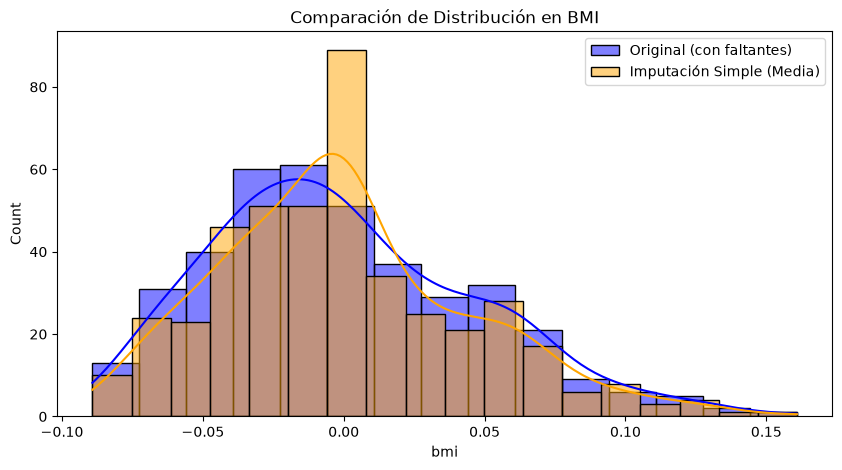

In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(data['bmi'].dropna(), label='Original (con faltantes)', color='blue', kde=True)
sns.histplot(data_simple['bmi'], label='Imputación Simple (Media)', color='orange', kde=True)
plt.title('Comparación de Distribución en BMI')
plt.legend()
plt.show()